In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier

print("Setup Successful!")

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning Libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

# Model Evaluation
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

Matplotlib is building the font cache; this may take a moment.


## Load Dataset


In [ ]:

df = pd.read_csv("Company_Data.csv")

In [5]:
print(df.head())

   Sales  CompPrice  Income  Advertising  Population  Price ShelveLoc  Age  \
0   9.50        138      73           11         276    120       Bad   42   
1  11.22        111      48           16         260     83      Good   65   
2  10.06        113      35           10         269     80    Medium   59   
3   7.40        117     100            4         466     97    Medium   55   
4   4.15        141      64            3         340    128       Bad   38   

   Education Urban   US  
0         17   Yes  Yes  
1         10   Yes  Yes  
2         12   Yes  Yes  
3         14   Yes  Yes  
4         13   Yes   No  


## Basic Information Of Dataset

In [6]:
print("\nShape of Dataset")
print(df.shape)

print("\nColumn Names")
print(df.columns)

print("\nInformation")
print(df.info())

print("\nSummary Statistics")
print(df.describe())

print("\nMissing Values")
print(df.isnull().sum())


Shape of Dataset
(400, 11)

Column Names
Index(['Sales', 'CompPrice', 'Income', 'Advertising', 'Population', 'Price',
       'ShelveLoc', 'Age', 'Education', 'Urban', 'US'],
      dtype='str')

Information
<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Sales        400 non-null    float64
 1   CompPrice    400 non-null    int64  
 2   Income       400 non-null    int64  
 3   Advertising  400 non-null    int64  
 4   Population   400 non-null    int64  
 5   Price        400 non-null    int64  
 6   ShelveLoc    400 non-null    str    
 7   Age          400 non-null    int64  
 8   Education    400 non-null    int64  
 9   Urban        400 non-null    str    
 10  US           400 non-null    str    
dtypes: float64(1), int64(7), str(3)
memory usage: 34.5 KB
None

Summary Statistics
            Sales   CompPrice      Income  Advertising  Population  \

In [7]:
print(df["Sales"].describe())

count    400.000000
mean       7.496325
std        2.824115
min        0.000000
25%        5.390000
50%        7.490000
75%        9.320000
max       16.270000
Name: Sales, dtype: float64


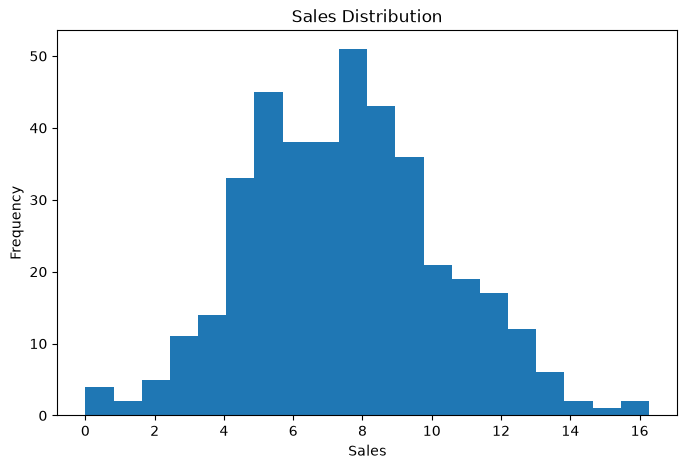

In [8]:
plt.figure(figsize=(8,5))
plt.hist(df["Sales"], bins=20)
plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

In [9]:
df["Sales"] = np.where(df["Sales"] > 8, "High", "Low")

In [11]:
print(df.head())

  Sales  CompPrice  Income  Advertising  Population  Price ShelveLoc  Age  \
0  High        138      73           11         276    120       Bad   42   
1  High        111      48           16         260     83      Good   65   
2  High        113      35           10         269     80    Medium   59   
3   Low        117     100            4         466     97    Medium   55   
4   Low        141      64            3         340    128       Bad   38   

   Education Urban   US  
0         17   Yes  Yes  
1         10   Yes  Yes  
2         12   Yes  Yes  
3         14   Yes  Yes  
4         13   Yes   No  


In [12]:
print(df["Sales"].value_counts())

Sales
Low     236
High    164
Name: count, dtype: int64


In [13]:
print(df.dtypes)

Sales            str
CompPrice      int64
Income         int64
Advertising    int64
Population     int64
Price          int64
ShelveLoc        str
Age            int64
Education      int64
Urban            str
US               str
dtype: object


In [14]:
encoder = LabelEncoder()

In [15]:
df["Sales"] = encoder.fit_transform(df["Sales"])

df["ShelveLoc"] = encoder.fit_transform(df["ShelveLoc"])

df["Urban"] = encoder.fit_transform(df["Urban"])

df["US"] = encoder.fit_transform(df["US"])

In [16]:
print(df.head())

   Sales  CompPrice  Income  Advertising  Population  Price  ShelveLoc  Age  \
0      0        138      73           11         276    120          0   42   
1      0        111      48           16         260     83          1   65   
2      0        113      35           10         269     80          2   59   
3      1        117     100            4         466     97          2   55   
4      1        141      64            3         340    128          0   38   

   Education  Urban  US  
0         17      1   1  
1         10      1   1  
2         12      1   1  
3         14      1   1  
4         13      1   0  


In [17]:
X = df.drop("Sales", axis=1)

In [18]:
y = df["Sales"]

In [19]:
print(X.head())

print(y.head())

   CompPrice  Income  Advertising  Population  Price  ShelveLoc  Age  \
0        138      73           11         276    120          0   42   
1        111      48           16         260     83          1   65   
2        113      35           10         269     80          2   59   
3        117     100            4         466     97          2   55   
4        141      64            3         340    128          0   38   

   Education  Urban  US  
0         17      1   1  
1         10      1   1  
2         12      1   1  
3         14      1   1  
4         13      1   0  
0    0
1    0
2    0
3    1
4    1
Name: Sales, dtype: int64


# Split Dataset


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Print Shapes

In [21]:
print(X_train.shape)

print(X_test.shape)

(320, 10)
(80, 10)


In [ ]:
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=4,
    random_state=42
)

In [23]:
# Train Model
model.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [24]:
y_pred = model.predict(X_test)

In [ ]:
# print(y_pred[:10])

[1 1 0 1 1 1 0 0 0 1]


In [26]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy =", accuracy)

Accuracy = 0.7625


In [27]:
cm = confusion_matrix(y_test, y_pred)

In [28]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.75      0.73      0.74        37
           1       0.77      0.79      0.78        43

    accuracy                           0.76        80
   macro avg       0.76      0.76      0.76        80
weighted avg       0.76      0.76      0.76        80



In [29]:
importance = pd.DataFrame({

    "Feature": X.columns,

    "Importance": model.feature_importances_

})

print(importance)

       Feature  Importance
0    CompPrice    0.032224
1       Income    0.078499
2  Advertising    0.208196
3   Population    0.018260
4        Price    0.284149
5    ShelveLoc    0.231993
6          Age    0.114201
7    Education    0.032477
8        Urban    0.000000
9           US    0.000000


In [37]:
y_pred_train=model.predict(X_train)

acc= classification_report(y_train,y_pred_train)
print(acc)

              precision    recall  f1-score   support

           0       0.76      0.76      0.76       127
           1       0.84      0.84      0.84       193

    accuracy                           0.81       320
   macro avg       0.80      0.80      0.80       320
weighted avg       0.81      0.81      0.81       320



<BarContainer object of 10 artists>

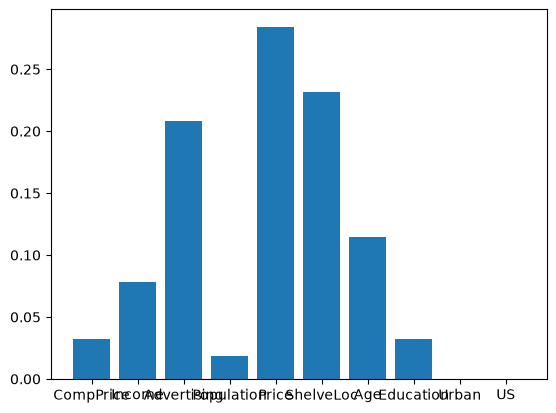

In [30]:
plt.bar(
importance["Feature"],
importance["Importance"]
)

[Text(0.44, 0.9, 'x[4] <= 92.5\nentropy = 0.969\nsamples = 320\nvalue = [127, 193]'),
 Text(0.2, 0.7, 'x[5] <= 0.5\nentropy = 0.675\nsamples = 45\nvalue = [37, 8]'),
 Text(0.32, 0.8, 'True  '),
 Text(0.08, 0.5, 'x[1] <= 57.0\nentropy = 1.0\nsamples = 12\nvalue = [6, 6]'),
 Text(0.04, 0.3, 'entropy = 0.0\nsamples = 4\nvalue = [0, 4]'),
 Text(0.12, 0.3, 'x[2] <= 9.5\nentropy = 0.811\nsamples = 8\nvalue = [6, 2]'),
 Text(0.08, 0.1, 'entropy = 1.0\nsamples = 4\nvalue = [2, 2]'),
 Text(0.16, 0.1, 'entropy = 0.0\nsamples = 4\nvalue = [4, 0]'),
 Text(0.32, 0.5, 'x[0] <= 101.0\nentropy = 0.33\nsamples = 33\nvalue = [31, 2]'),
 Text(0.28, 0.3, 'x[3] <= 227.0\nentropy = 0.811\nsamples = 8\nvalue = [6, 2]'),
 Text(0.24, 0.1, 'entropy = 1.0\nsamples = 4\nvalue = [2, 2]'),
 Text(0.32, 0.1, 'entropy = 0.0\nsamples = 4\nvalue = [4, 0]'),
 Text(0.36, 0.3, 'entropy = 0.0\nsamples = 25\nvalue = [25, 0]'),
 Text(0.68, 0.7, 'x[5] <= 0.5\nentropy = 0.912\nsamples = 275\nvalue = [90, 185]'),
 Text(0.56, 0.8

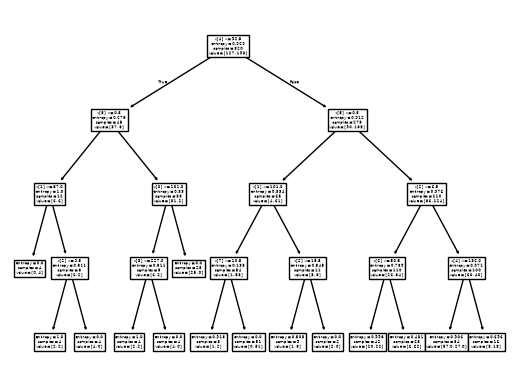

In [32]:
plot_tree(model)